# DeepVCF tutorial

This notebook demonstrates three steps:

1. Train DeepVCF+MP.
2. Evaluate the trained model on the external datasets and compare with baseline results.
3. Use the same model to predict anthranilate targets and display their ranks in GEM-covered and GEM-uncovered groups.

Run the cells in order using the `deepvcf` kernel on a GPU.


## Setup

From the repository root:

```bash
conda activate deepvcf
jupyter lab tutorial.ipynb
```

The example uses seed 1 and five folds.


In [1]:
import logging
import sys
from pathlib import Path
from tempfile import TemporaryDirectory

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'code/model.py').is_file())
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / 'code'))
from knowledge import KGProcessor
from cf_data import CFDataProcessor, CFTrainDataProcessor
from model import DeepVCFModel
from utils import set_seeds
from reproducibility.external_evaluation.common import load_external_filter_positive_set

logging.basicConfig(level=logging.INFO, format='%(message)s', force=True)
SEED = 1
DEVICE = 'cuda:0'
K = 5

KG_PATH = ROOT / 'data/processed/kg/ECO/kg_enhanced.txt'
TRAIN_PATH = ROOT / 'data/processed/cf/train/train.txt'
MP_PATH = ROOT / 'data/processed/cf/mechanistic_pretraining/ECO_FSEOF_1_3.txt'
EXTERNAL_ROOT = ROOT / 'data/processed/cf/evaluation/external_test'
FILTER_PATHS = [
    ROOT / 'data/processed/cf/datasets' / name
    for name in ['ECO_2023.txt', 'ECO_2024.txt', 'ECO_before_2023.txt', 'laser.txt']
]
print('Python:', sys.executable)
print('Device:', DEVICE, '| seed:', SEED, '| folds:', K)


Python: /home/shengkun/miniforge3/envs/deepvcf/bin/python
Device: cuda:0 | seed: 1 | folds: 5


In [2]:
config = {
    'device': DEVICE, 'seed': SEED, 'ensemble': True, 'k': K,
    'hidden_dim': 300, 'hidden_channels': 300, 'dropout': 0.1,
    'drn_lr': 1e-3, 'drn_wd': 1e-5, 'drn_batch_size': 1024,
    'drn_num_epochs': 200, 'drn_eval_interval': 1, 'drn_patience': 20,
    'drn_num_neg': 100, 'drn_neg_sampling': 'adversarial',
    'drn_adv_temperature': 1.0, 'drn_margin': 1.0,
    'tpn_lr': 5e-5, 'tpn_wd': 1e-5, 'tpn_batch_size': 128,
    'tpn_num_epochs': 500, 'tpn_patience': 30,
    'tpn_loss': 'CE', 'tpn_early_stop_metric': 'unfiltered_gene_mrr',
}
MP_EPOCHS = 50
MP_BATCH_SIZE = 1024


## 1. Train DeepVCF+MP

Load the enhanced ECO KG and create the model. CF inputs have four tab-separated columns without a header: `gene, modification, metabolite, label`.


In [3]:
# Temporary indexing files are shared by the KG and CF data processors.
workspace = TemporaryDirectory()
index_root = Path(workspace.name)
set_seeds(SEED)

graph, kg_metadata, drn_splits = KGProcessor(
    kg_path={'ECO': str(KG_PATH)}, index_root=index_root,
    no_inverse_relations={'PPI'}, seed=SEED,
).process(num_drn_folds=K)

model = DeepVCFModel(
    config=config, num_nodes=graph.num_nodes,
    num_relations=graph.num_edge_type, task_rel=graph.task_rel,
    kg_metadata=kg_metadata, species='ECO',
).to(DEVICE)

print('Nodes:', graph.num_nodes, '| relations:', graph.num_edge_type)
print('Ensemble folds:', len(model.folds))


KG ECO: 99014 triples.


Nodes: 17171 | relations: 29
Ensemble folds: 5


### Train the DRN

Learn graph representations for each fold. Training progress appears below.


In [4]:
model.train_drn(drn_splits)


DRN training started for fold #1.
100%|██████████| 145/145 [00:12<00:00, 11.84it/s]
DRN epoch: 00001, loss: 0.9483
100%|██████████| 145/145 [00:13<00:00, 11.11it/s]
DRN epoch: 00002, loss: 0.6836
100%|██████████| 145/145 [00:13<00:00, 11.15it/s]
DRN epoch: 00003, loss: 0.5119
100%|██████████| 145/145 [00:12<00:00, 11.17it/s]
DRN epoch: 00004, loss: 0.3954
100%|██████████| 145/145 [00:13<00:00, 11.03it/s]
DRN epoch: 00005, loss: 0.2975
100%|██████████| 145/145 [00:11<00:00, 12.09it/s]
DRN epoch: 00006, loss: 0.2290
100%|██████████| 145/145 [00:13<00:00, 11.10it/s]
DRN epoch: 00007, loss: 0.1831
100%|██████████| 145/145 [00:12<00:00, 11.22it/s]
DRN epoch: 00008, loss: 0.1529
100%|██████████| 145/145 [00:13<00:00, 11.12it/s]
DRN epoch: 00009, loss: 0.1318
100%|██████████| 145/145 [00:12<00:00, 11.18it/s]
DRN epoch: 00010, loss: 0.1167
100%|██████████| 145/145 [00:13<00:00, 11.10it/s]
DRN epoch: 00011, loss: 0.1047
100%|██████████| 8/8 [00:01<00:00,  5.10it/s]
Improved DRN validation typed

### Mechanistic pretraining

Train each TPN on the FSEOF data for 50 epochs, with fixed DRN embeddings.


In [5]:
mp_data = CFDataProcessor(MP_PATH, index_root, split='train').process()
model.train_tpn([mp_data] * K, fixed_epochs=MP_EPOCHS, batch_size=MP_BATCH_SIZE)


CF train rows: 209833.
Target prediction network training started.
Training TPN for fold #1.
TPN training started.
Fixed-epoch TPN training enabled: 50 epochs without early stopping.
100%|██████████| 205/205 [00:03<00:00, 53.88it/s]
TPN epoch: 00001, loss: 0.4813
100%|██████████| 205/205 [00:03<00:00, 54.33it/s]
TPN epoch: 00002, loss: 0.2874
100%|██████████| 205/205 [00:03<00:00, 55.04it/s]
TPN epoch: 00003, loss: 0.2407
100%|██████████| 205/205 [00:03<00:00, 54.32it/s]
TPN epoch: 00004, loss: 0.2173
100%|██████████| 205/205 [00:03<00:00, 56.08it/s]
TPN epoch: 00005, loss: 0.2019
100%|██████████| 205/205 [00:03<00:00, 54.38it/s]
TPN epoch: 00006, loss: 0.1891
100%|██████████| 205/205 [00:03<00:00, 54.38it/s]
TPN epoch: 00007, loss: 0.1800
100%|██████████| 205/205 [00:03<00:00, 56.04it/s]
TPN epoch: 00008, loss: 0.1729
 26%|██▋       | 54/205 [00:00<00:02, 56.14it/s]

100%|██████████| 205/205 [00:03<00:00, 54.24it/s]
TPN epoch: 00009, loss: 0.1669
100%|██████████| 205/205 [00:03<00:00, 56.01it/s]
TPN epoch: 00010, loss: 0.1610
100%|██████████| 205/205 [00:03<00:00, 54.40it/s]
TPN epoch: 00011, loss: 0.1564
100%|██████████| 205/205 [00:03<00:00, 55.93it/s]
TPN epoch: 00012, loss: 0.1521
100%|██████████| 205/205 [00:04<00:00, 45.23it/s]
TPN epoch: 00013, loss: 0.1481
100%|██████████| 205/205 [00:03<00:00, 54.37it/s]
TPN epoch: 00014, loss: 0.1449
100%|██████████| 205/205 [00:03<00:00, 56.16it/s]
TPN epoch: 00015, loss: 0.1417
100%|██████████| 205/205 [00:03<00:00, 54.46it/s]
TPN epoch: 00016, loss: 0.1391
100%|██████████| 205/205 [00:03<00:00, 56.06it/s]
TPN epoch: 00017, loss: 0.1367
100%|██████████| 205/205 [00:03<00:00, 54.44it/s]
TPN epoch: 00018, loss: 0.1344
100%|██████████| 205/205 [00:03<00:00, 56.03it/s]
TPN epoch: 00019, loss: 0.1324
100%|██████████| 205/205 [00:03<00:00, 54.44it/s]
TPN epoch: 00020, loss: 0.1303
100%|██████████| 205/205 [00

### Fine-tune the TPN

Use five CF training/validation folds. Early stopping uses validation gene MRR.


In [6]:
cf_folds, _ = CFTrainDataProcessor(
    train_path=TRAIN_PATH, index_root=index_root,
    ensemble=True, k=K, seed=SEED,
).process()
set_seeds(SEED)
model.train_tpn(cf_folds)
model.eval()


CF fold 1: train=7098, valid=1775.
CF fold 2: train=7098, valid=1775.
CF fold 3: train=7098, valid=1775.
CF fold 4: train=7099, valid=1774.
CF fold 5: train=7099, valid=1774.
Target prediction network training started.
Training TPN for fold #1.
TPN training started.
100%|██████████| 56/56 [00:00<00:00, 69.91it/s]
TPN epoch: 00001, loss: 0.6168
TPN validation unfiltered gene MRR — GEM: 0.0311, non-GEM: 0.0353, heterologous: n/a, mean: 0.0332.
Improved TPN validation unfiltered_gene_mrr: 0.0332.
100%|██████████| 56/56 [00:00<00:00, 71.92it/s]
TPN epoch: 00002, loss: 0.4001
TPN validation unfiltered gene MRR — GEM: 0.0615, non-GEM: 0.0492, heterologous: n/a, mean: 0.0553.
Improved TPN validation unfiltered_gene_mrr: 0.0553.
100%|██████████| 56/56 [00:00<00:00, 71.30it/s]
TPN epoch: 00003, loss: 0.3647
TPN validation unfiltered gene MRR — GEM: 0.0705, non-GEM: 0.0566, heterologous: n/a, mean: 0.0635.
Improved TPN validation unfiltered_gene_mrr: 0.0635.
100%|██████████| 56/56 [00:00<00:00, 

DeepVCFModel(
  (folds): ModuleList(
    (0-4): 5 x ModuleDict(
      (drn): DeepRepresentationNetwork(
        (decoder): DistMult()
      )
      (tpn): TargetPredictionNetwork(
        (augment_src): Sequential(
          (0): Linear(in_features=300, out_features=300, bias=True)
          (1): LayerNorm((300,), eps=1e-05, elementwise_affine=True)
          (2): ReLU(inplace=True)
          (3): Dropout(p=0.1, inplace=False)
        )
        (augment_dst): Sequential(
          (0): Linear(in_features=300, out_features=300, bias=True)
          (1): LayerNorm((300,), eps=1e-05, elementwise_affine=True)
          (2): ReLU(inplace=True)
          (3): Dropout(p=0.1, inplace=False)
        )
        (augment_diff): Sequential(
          (0): Linear(in_features=300, out_features=100, bias=True)
          (1): LayerNorm((100,), eps=1e-05, elementwise_affine=True)
          (2): ReLU(inplace=True)
          (3): Dropout(p=0.1, inplace=False)
        )
        (augment_sqdiff): Sequential

## 2. Evaluate the external datasets

Compute AUROC, AUPR, and filtered gene Hits@10/20/30 for GEM-covered and GEM-uncovered tests. Ranking removes other known positives using the four filter datasets. The ensemble averages fold probabilities before computing metrics.


In [10]:
filter_pos_set, _ = load_external_filter_positive_set(FILTER_PATHS, kg_metadata)
external_tests = {}
external_data = {}
external_results = {}
metric_rows = []

for group, directory in [('GEM-covered', 'gem_gene'), ('GEM-uncovered', 'non_gem_gene')]:
    path = EXTERNAL_ROOT / directory / 'head_corrupt_test.txt'
    external_tests[group] = pd.read_csv(
        path, sep='\t', header=None,
        names=['gene', 'modification', 'metabolite', 'label'],
    )
    test_data = CFDataProcessor(path, index_root, split='test').process()
    external_data[group] = test_data
    binary = model.evaluate_deepvcf(
        species='ECO', test_data=test_data, labels=test_data.test_label, test_type='binary',
    )
    ranking = model.evaluate_deepvcf(
        species='ECO', test_data=test_data, labels=test_data.test_label,
        test_type='ranking', filter_pos_set=filter_pos_set, ks=(10, 20, 30),
    )
    external_results[group] = {'binary': binary, 'ranking': ranking}
    scores = binary['ensemble']['binary']['overall']
    ranks = ranking['ensemble']['target_gene_ranking']
    metric_rows.append({
        'Gene group': group, 'AUROC': scores['auroc'], 'AUPR': scores['aupr'],
        **{f'Hits@{k}': ranks[f'gene_hit@{k}'] for k in (10, 20, 30)},
    })

display(pd.DataFrame(metric_rows).round(4))


CF test rows: 1251.
CF test rows: 160.


,Gene group,AUROC,AUPR,Hits@10,Hits@20,Hits@30
0,GEM-covered,0.8833,0.7554,0.2898,0.3758,0.4522
1,GEM-uncovered,0.7302,0.6040,0.2000,0.2750,0.3000


### Train and evaluate ML baselines

Fit LR, MLP, and RF on the complete CF training dataset using the first fold's frozen DRN embeddings. The classifiers reuse the same external tests, gene candidate pools, and known-positive filter as DeepVCF.

The code reuses the existing baseline implementation. Each baseline is one classifier; DeepVCF+MP uses its five-fold ensemble. All rows in the comparison below use the current `SEED`. Edit `BASELINES` to run a subset, for example `['lr']`.


In [11]:
from reproducibility.external_evaluation.evaluate_ml_baselines import (
    build_estimator, extract_features, evaluate_estimator,
)

BASELINES = ['lr', 'mlp', 'rf']
embeddings = model.get_drn_embeddings(fold_index=0).detach().cpu()
full_train, _ = CFTrainDataProcessor(TRAIN_PATH, index_root, seed=SEED).process_full()
train_features = extract_features(
    embeddings, full_train.train_edge_index, full_train.train_edge_type, model.task_rel,
)
train_labels = full_train.train_label.numpy().astype(int)
candidate_pools = kg_metadata['node_group_ids_by_species']['ECO']
baseline_rows = []

for name in BASELINES:
    print('Training', name.upper())
    estimator = build_estimator(name, SEED)
    estimator.fit(train_features, train_labels)
    for group, test_data in external_data.items():
        result = evaluate_estimator(
            estimator, test_data, embeddings, model.task_rel,
            candidate_pools, filter_pos_set, include_ranking=True,
        )
        scores = result['binary']['overall']
        ranks = result['target_gene_ranking']
        baseline_rows.append({
            'Gene group': group, 'Method': name.upper() + ' (DRN)',
            'AUROC': scores['auroc'], 'AUPR': scores['aupr'],
            **{f'Hits@{k}': ranks[f'gene_hit@{k}'] for k in (10, 20, 30)},
        })

comparison = pd.concat([
    pd.DataFrame(metric_rows).assign(Method='DeepVCF+MP'),
    pd.DataFrame(baseline_rows),
], ignore_index=True)
display(comparison[
    ['Gene group', 'Method', 'AUROC', 'AUPR', 'Hits@10', 'Hits@20', 'Hits@30']
].sort_values('Gene group', kind='stable').round(4))


Complete CF training rows: 8873.


Training LR
Training MLP
Training RF


,Gene group,Method,AUROC,AUPR,Hits@10,Hits@20,Hits@30
0,GEM-covered,DeepVCF+MP,0.8833,0.7554,0.2898,0.3758,0.4522
2,GEM-covered,LR (DRN),0.7047,0.4409,0.0318,0.0764,0.1210
4,GEM-covered,MLP (DRN),0.7504,0.5330,0.0669,0.1146,0.1720
6,GEM-covered,RF (DRN),0.7298,0.5032,0.0732,0.1338,0.1847
1,GEM-uncovered,DeepVCF+MP,0.7302,0.6040,0.2000,0.2750,0.3000
3,GEM-uncovered,LR (DRN),0.6833,0.3718,0.0000,0.0000,0.0000
5,GEM-uncovered,MLP (DRN),0.7216,0.4321,0.1250,0.1500,0.1500
7,GEM-uncovered,RF (DRN),0.6189,0.4293,0.1000,0.1500,0.1500


### Evaluate mechanistic baselines

Evaluate the supplied **FSEOF, FVSEOF, and iBridge prediction tables** on the same GEM-covered external test, using the model's GEM-covered candidate pool and the same known-positive filter datasets. This step uses the existing scoring and evaluation functions; it does not rerun metabolic optimization.

These methods support GEM-covered targets only. Unranked genes receive the evaluator's seed-controlled low scores. Their results are added to the comparison below.


In [12]:
from reproducibility.external_evaluation import evaluate_mechanistic_baselines as mech

eco = mech.SPECIES_CONFIG['ECO']
gem_test = mech.read_cf(EXTERNAL_ROOT / 'gem_gene/head_corrupt_test.txt')
filter_data, _ = mech.load_filter_data(FILTER_PATHS)
gem_genes = sorted(kg_metadata['node_groups_by_species']['ECO']['gem_genes'])
indexed = mech.build_index_data(filter_data, gem_test, gem_genes)
metabolites = sorted(set(gem_test.metabolite))
gene_mapping = mech.load_species_gene_mapping('ECO', eco['gene_info_path'], gem_genes)
reaction_to_genes = mech.load_reaction_gene_mapping(eco['model_path'], gene_mapping)

method_scores = {
    'FSEOF': mech.load_fseof_scores(eco['fseof_root'], metabolites, gene_mapping),
    'FVSEOF': mech.load_fvseof_scores(
        mech.BASELINES_ROOT / 'FVSEOF/ECO' / eco['model'], metabolites, gene_mapping,
    ),
    'iBridge': mech.load_ibridge_scores(eco['ibridge_root'], metabolites, reaction_to_genes),
}
mechanistic_rows = []
for name, supplied_scores in method_scores.items():
    scores = mech.complete_scores(supplied_scores, metabolites, gem_genes, SEED)
    result = mech.evaluate(scores, indexed, device=DEVICE)
    binary = result['binary']
    ranks = result['target_gene_ranking']
    mechanistic_rows.append({
        'Gene group': 'GEM-covered', 'Method': name,
        'AUROC': binary['auroc'], 'AUPR': binary['aupr'],
        **{f'Hits@{k}': ranks[f'gene_hit@{k}'] for k in (10, 20, 30)},
    })

full_comparison = pd.concat([comparison, pd.DataFrame(mechanistic_rows)], ignore_index=True)
display(full_comparison[
    ['Gene group', 'Method', 'AUROC', 'AUPR', 'Hits@10', 'Hits@20', 'Hits@30']
].sort_values('Gene group', kind='stable').round(4))


,Gene group,Method,AUROC,AUPR,Hits@10,Hits@20,Hits@30
0,GEM-covered,DeepVCF+MP,0.8833,0.7554,0.2898,0.3758,0.4522
2,GEM-covered,LR (DRN),0.7047,0.4409,0.0318,0.0764,0.1210
4,GEM-covered,MLP (DRN),0.7504,0.5330,0.0669,0.1146,0.1720
6,GEM-covered,RF (DRN),0.7298,0.5032,0.0732,0.1338,0.1847
8,GEM-covered,FSEOF,0.5978,0.4152,0.1306,0.1592,0.1656
9,GEM-covered,FVSEOF,0.6787,0.4461,0.1146,0.1752,0.2038
10,GEM-covered,iBridge,0.5729,0.3668,0.0159,0.0446,0.0860
1,GEM-uncovered,DeepVCF+MP,0.7302,0.6040,0.2000,0.2750,0.3000
3,GEM-uncovered,LR (DRN),0.6833,0.3718,0.0000,0.0000,0.0000
5,GEM-uncovered,MLP (DRN),0.7216,0.4321,0.1250,0.1500,0.1500


### Baseline reference results

The evaluation above reports the ensemble for **one seed**. The following tables provide **five-seed mean ± sample standard deviation** for the same external tests. They are a reference for interpreting the current run, rather than a paired single-seed comparison.

DeepVCF entries come from the current implementation's five-seed experiments. ML and mechanistic entries come from archived benchmark evaluations using identical CF training, external test, and ranking-filter files. Mechanistic methods support GEM-covered targets only. ML methods use DRN or fixed random embeddings, as indicated.

**GEM-covered genes**

| Method | AUROC | AUPR | Hits@10 | Hits@20 | Hits@30 |
|---|---:|---:|---:|---:|---:|
| DeepVCF+MP | 0.8824 ± 0.0022 | 0.7574 ± 0.0077 | 0.2873 ± 0.0266 | 0.3739 ± 0.0253 | 0.4459 ± 0.0211 |
| DeepVCF | 0.8517 ± 0.0094 | 0.6916 ± 0.0135 | 0.2261 ± 0.0205 | 0.3134 ± 0.0129 | 0.3834 ± 0.0230 |
| LR (DRN) | 0.7310 ± 0.0149 | 0.4784 ± 0.0224 | 0.0389 ± 0.0194 | 0.0879 ± 0.0217 | 0.1554 ± 0.0298 |
| MLP (DRN) | 0.7617 ± 0.0173 | 0.5624 ± 0.0418 | 0.0866 ± 0.0176 | 0.1478 ± 0.0210 | 0.2013 ± 0.0242 |
| RF (DRN) | 0.7275 ± 0.0124 | 0.5014 ± 0.0176 | 0.0796 ± 0.0087 | 0.1382 ± 0.0094 | 0.1834 ± 0.0140 |
| LR (random) | 0.6314 ± 0.0149 | 0.4001 ± 0.0143 | 0.0185 ± 0.0145 | 0.0529 ± 0.0217 | 0.0994 ± 0.0271 |
| MLP (random) | 0.6921 ± 0.0090 | 0.4686 ± 0.0073 | 0.0771 ± 0.0141 | 0.1408 ± 0.0143 | 0.1911 ± 0.0179 |
| RF (random) | 0.6353 ± 0.0031 | 0.4162 ± 0.0067 | 0.0739 ± 0.0104 | 0.1299 ± 0.0104 | 0.1631 ± 0.0140 |
| FSEOF | 0.5758 ± 0.0185 | 0.4064 ± 0.0127 | 0.1287 ± 0.0017 | 0.1573 ± 0.0036 | 0.1656 ± 0.0023 |
| FVSEOF | 0.6753 ± 0.0100 | 0.4455 ± 0.0033 | 0.1153 ± 0.0014 | 0.1771 ± 0.0017 | 0.2076 ± 0.0042 |
| iBridge | 0.5772 ± 0.0092 | 0.3728 ± 0.0058 | 0.0166 ± 0.0014 | 0.0465 ± 0.0017 | 0.0898 ± 0.0027 |

**GEM-uncovered genes**

| Method | AUROC | AUPR | Hits@10 | Hits@20 | Hits@30 |
|---|---:|---:|---:|---:|---:|
| DeepVCF+MP | 0.7453 ± 0.0139 | 0.6199 ± 0.0139 | 0.1900 ± 0.0224 | 0.2550 ± 0.0326 | 0.2900 ± 0.0137 |
| DeepVCF | 0.7285 ± 0.0197 | 0.6242 ± 0.0305 | 0.2000 ± 0.0250 | 0.2250 ± 0.0177 | 0.2600 ± 0.0224 |
| LR (DRN) | 0.6981 ± 0.0282 | 0.3949 ± 0.0172 | 0.0000 ± 0.0000 | 0.0100 ± 0.0224 | 0.0100 ± 0.0224 |
| MLP (DRN) | 0.7296 ± 0.0378 | 0.5172 ± 0.0668 | 0.1100 ± 0.0418 | 0.1850 ± 0.0487 | 0.2200 ± 0.0447 |
| RF (DRN) | 0.6724 ± 0.0408 | 0.4904 ± 0.0657 | 0.1550 ± 0.0671 | 0.1650 ± 0.0602 | 0.1750 ± 0.0586 |
| LR (random) | 0.5820 ± 0.0358 | 0.3327 ± 0.0524 | 0.0050 ± 0.0112 | 0.0150 ± 0.0224 | 0.0250 ± 0.0250 |
| MLP (random) | 0.6339 ± 0.0414 | 0.4069 ± 0.1002 | 0.0550 ± 0.0411 | 0.0900 ± 0.0454 | 0.1100 ± 0.0285 |
| RF (random) | 0.6118 ± 0.0470 | 0.4103 ± 0.0476 | 0.0850 ± 0.0285 | 0.0900 ± 0.0379 | 0.1100 ± 0.0285 |


## 3. Predict targets for anthranilate

Use the same `model` to rank KO and OE interventions for `Metabolite:anth_c`. Known positives are pooled from the CF training set, the four ranking-filter datasets, and the two external tests. An intervention counts as present in CF training when the same gene, modification, and metabolite occur with label 1 in `TRAIN_PATH`.

Set `SAVE_PREDICTIONS = True` to save the ranked prediction table as `<PRODUCT>.tsv`. The table includes the gene group, rank, and flags for known positives and CF training membership.

Run the cells below after training to generate the ranking figure and prediction table.


In [13]:
PRODUCT = 'Metabolite:anth_c'
SAVE_PREDICTIONS = True

training_positives, _ = load_external_filter_positive_set([TRAIN_PATH], kg_metadata)
external_paths = [
    EXTERNAL_ROOT / group / 'head_corrupt_test.txt'
    for group in ('gem_gene', 'non_gem_gene')
]
external_positives, _ = load_external_filter_positive_set(external_paths, kg_metadata)
known_positives = training_positives | filter_pos_set | external_positives

node_names = {index: node for node, index in kg_metadata['node_to_id'].items()}
modifications = {index: relation for relation, index in kg_metadata['relation_to_id'].items()}
product_index = kg_metadata['node_to_id'][PRODUCT]

def target_pairs(triples):
    return {
        (node_names[head].split(':', 1)[-1], modifications[relation])
        for head, relation, tail in triples if tail == product_index
    }

known_pairs = target_pairs(known_positives)
training_pairs = target_pairs(training_positives)


In [14]:
predictions = model.genome_scale_prediction(
    species='ECO', query_met=[PRODUCT], gene_group='all',
)[PRODUCT]
predictions['gene_group'] = predictions['gene_group'].replace({
    'GEM': 'GEM-covered', 'non-GEM': 'GEM-uncovered',
})
predictions['rank'] = predictions.groupby(
    ['gene_group', 'modification']
).deepvcf_score.rank(method='min', ascending=False).astype(int)

candidate_pairs = list(zip(predictions.gene, predictions.modification))
predictions['known_positive'] = [pair in known_pairs for pair in candidate_pairs]
predictions['in_cf_training'] = [pair in training_pairs for pair in candidate_pairs]

if SAVE_PREDICTIONS:
    predictions.to_csv(Path.cwd() / f'{PRODUCT}.tsv', sep='\t', index=False)

known_targets = predictions.loc[predictions.known_positive, [
    'gene_group', 'modification', 'gene', 'rank', 'in_cf_training',
]].sort_values(['gene_group', 'modification', 'rank'])
display(known_targets)

for (group, modification), candidates in predictions.groupby(['gene_group', 'modification']):
    print(group, '|', modification)
    display(candidates.sort_values(['rank', 'gene']).head(10))


,gene_group,modification,gene,rank,in_cf_training
1880,GEM-covered,knock out,P21599,1,False
3224,GEM-covered,knock out,P69786,2,False
143,GEM-covered,knock out,P05041,17,False
2616,GEM-covered,knock out,P38051,61,False
3602,GEM-covered,knock out,P76350,400,False
5897,GEM-covered,overexpress,P15770,1,False
4362,GEM-covered,overexpress,P07639,2,False
4201,GEM-covered,overexpress,P00888,3,False
5022,GEM-covered,overexpress,P0AB91,4,True
4285,GEM-covered,overexpress,P05194,5,False


GEM-covered | knock out


,query_metabolite,gene,gene_group,modification,deepvcf_score,ensemble_variance,fold_1_score,fold_2_score,fold_3_score,fold_4_score,fold_5_score,rank,known_positive,in_cf_training
1880,Metabolite:anth_c,P21599,GEM-covered,knock out,0.563904,0.106488,0.032646,0.836236,0.498636,0.970160,0.481841,1,True,False
3224,Metabolite:anth_c,P69786,GEM-covered,knock out,0.491968,0.166560,0.006470,0.818275,0.008209,0.971397,0.655491,2,True,False
1118,Metabolite:anth_c,P0AD61,GEM-covered,knock out,0.457239,0.112603,0.044781,0.660511,0.136076,0.954571,0.490259,3,False,False
519,Metabolite:anth_c,P0A853,GEM-covered,knock out,0.453194,0.118923,0.122136,0.694544,0.106366,0.996419,0.346503,4,False,False
781,Metabolite:anth_c,P0AAD2,GEM-covered,knock out,0.439630,0.117322,0.040417,0.680959,0.072981,0.922125,0.481670,5,False,False
318,Metabolite:anth_c,P0A6A3,GEM-covered,knock out,0.428215,0.107618,0.000279,0.280440,0.321278,0.980115,0.558961,6,False,False
274,Metabolite:anth_c,P08839,GEM-covered,knock out,0.421745,0.123878,0.003840,0.646695,0.145088,0.978527,0.334575,7,False,False
1907,Metabolite:anth_c,P23173,GEM-covered,knock out,0.391561,0.132685,0.002174,0.648193,0.014812,0.941443,0.351185,8,False,False
129,Metabolite:anth_c,P04693,GEM-covered,knock out,0.362589,0.139272,0.018117,0.584084,0.000210,0.979122,0.231411,9,False,False
70,Metabolite:anth_c,P00904,GEM-covered,knock out,0.349832,0.139686,0.038918,0.553071,0.000825,0.987056,0.169290,10,False,False


GEM-covered | overexpress


,query_metabolite,gene,gene_group,modification,deepvcf_score,ensemble_variance,fold_1_score,fold_2_score,fold_3_score,fold_4_score,fold_5_score,rank,known_positive,in_cf_training
5897,Metabolite:anth_c,P15770,GEM-covered,overexpress,0.947948,0.004327,0.982121,0.961660,0.988618,0.989410,0.817930,1,True,False
4362,Metabolite:anth_c,P07639,GEM-covered,overexpress,0.947447,0.005147,0.982098,0.962390,0.990816,0.996119,0.805809,2,True,False
4201,Metabolite:anth_c,P00888,GEM-covered,overexpress,0.939145,0.006827,0.984857,0.948665,0.990890,0.994178,0.777136,3,True,False
5022,Metabolite:anth_c,P0AB91,GEM-covered,overexpress,0.937137,0.008849,0.987466,0.962999,0.989937,0.994986,0.750297,4,True,True
4285,Metabolite:anth_c,P05194,GEM-covered,overexpress,0.928644,0.007308,0.977439,0.954155,0.976102,0.976948,0.758574,5,True,False
4824,Metabolite:anth_c,P0A9J8,GEM-covered,overexpress,0.927569,0.005079,0.958284,0.918055,0.986713,0.981298,0.793496,6,False,False
5836,Metabolite:anth_c,P12008,GEM-covered,overexpress,0.922703,0.010114,0.973644,0.953119,0.972096,0.991604,0.723052,7,True,False
6213,Metabolite:anth_c,P27302,GEM-covered,overexpress,0.919534,0.010524,0.969735,0.938259,0.982513,0.989752,0.717409,8,True,True
4569,Metabolite:anth_c,P0A796,GEM-covered,overexpress,0.897323,0.005727,0.881584,0.904440,0.958485,0.978788,0.763319,9,False,False
6536,Metabolite:anth_c,P33570,GEM-covered,overexpress,0.887004,0.013674,0.935406,0.882021,0.968371,0.985226,0.663997,10,False,False


GEM-uncovered | knock out


,query_metabolite,gene,gene_group,modification,deepvcf_score,ensemble_variance,fold_1_score,fold_2_score,fold_3_score,fold_4_score,fold_5_score,rank,known_positive,in_cf_training
224,Metabolite:anth_c,P07604,GEM-uncovered,knock out,0.676885,0.036647,0.697792,0.736441,0.513091,0.991453,0.445646,1,True,False
1041,Metabolite:anth_c,P0ACJ8,GEM-uncovered,knock out,0.455846,0.136526,0.015766,0.715714,0.854367,0.001164,0.692218,2,False,False
109,Metabolite:anth_c,P03024,GEM-uncovered,knock out,0.434358,0.112600,0.120867,0.815002,0.071843,0.851109,0.312972,3,False,False
1775,Metabolite:anth_c,P16528,GEM-uncovered,knock out,0.365027,0.113960,0.000453,0.399108,0.001088,0.888531,0.535952,4,False,False
3432,Metabolite:anth_c,P76016,GEM-uncovered,knock out,0.358271,0.121918,0.000259,0.358144,0.000854,0.937021,0.495078,5,False,False
707,Metabolite:anth_c,P0A9Q1,GEM-uncovered,knock out,0.354698,0.084968,0.001841,0.670880,0.011089,0.615493,0.474188,6,False,False
528,Metabolite:anth_c,P0A881,GEM-uncovered,knock out,0.345517,0.118089,0.029576,0.871553,0.145705,0.045470,0.635278,7,True,False
108,Metabolite:anth_c,P03023,GEM-uncovered,knock out,0.345316,0.082028,0.016148,0.774496,0.112424,0.246640,0.576871,8,False,False
3945,Metabolite:anth_c,P77730,GEM-uncovered,knock out,0.286715,0.087462,0.000186,0.292305,0.000034,0.807058,0.333992,9,False,False
991,Metabolite:anth_c,P0AC51,GEM-uncovered,knock out,0.275908,0.143783,0.000121,0.016325,0.000197,0.973451,0.389444,10,False,False


GEM-uncovered | overexpress


,query_metabolite,gene,gene_group,modification,deepvcf_score,ensemble_variance,fold_1_score,fold_2_score,fold_3_score,fold_4_score,fold_5_score,rank,known_positive,in_cf_training
4571,Metabolite:anth_c,P0A7A2,GEM-uncovered,overexpress,0.251980,0.073392,0.304203,0.002771,0.001555,0.739625,0.211746,1,False,False
5781,Metabolite:anth_c,P0DP89,GEM-uncovered,overexpress,0.251889,0.101819,0.013489,0.013917,0.841779,0.338683,0.051577,2,False,False
5173,Metabolite:anth_c,P0ACI3,GEM-uncovered,overexpress,0.186242,0.130748,0.003791,0.006663,0.000532,0.909392,0.010832,3,False,False
4783,Metabolite:anth_c,P0A988,GEM-uncovered,overexpress,0.167719,0.068105,0.001953,0.674484,0.000038,0.000137,0.161984,4,False,False
5812,Metabolite:anth_c,P11071,GEM-uncovered,overexpress,0.158321,0.027967,0.314064,0.028272,0.001914,0.042488,0.404867,5,False,False
4215,Metabolite:anth_c,P00954,GEM-uncovered,overexpress,0.137753,0.046571,0.000116,0.038260,0.006736,0.077819,0.565833,6,False,False
4360,Metabolite:anth_c,P07604,GEM-uncovered,overexpress,0.137461,0.022964,0.093494,0.085243,0.074868,0.000471,0.433229,7,False,False
7012,Metabolite:anth_c,P45795,GEM-uncovered,overexpress,0.133853,0.070084,0.000260,0.001096,0.004582,0.000019,0.663310,8,False,False
5453,Metabolite:anth_c,P0AES6,GEM-uncovered,overexpress,0.127041,0.033165,0.003397,0.469377,0.000125,0.000455,0.161852,9,False,False
4709,Metabolite:anth_c,P0A8M0,GEM-uncovered,overexpress,0.126097,0.060789,0.000576,0.008082,0.000028,0.002625,0.619173,10,False,False


### Display known-positive ranks by gene group and intervention

The panels separate KO and OE within each gene group. Color shows whether the known-positive intervention appears in the CF training set. The ranks use all candidates in each panel.


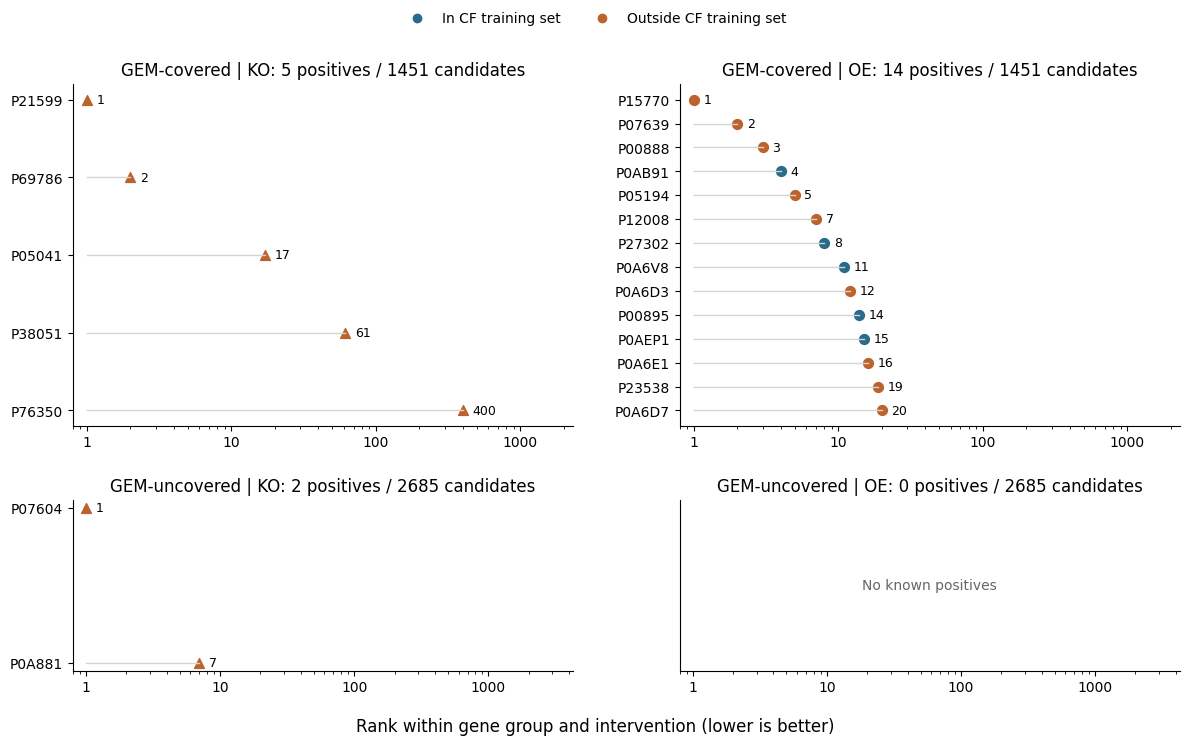

In [15]:
from matplotlib.lines import Line2D

groups = ('GEM-covered', 'GEM-uncovered')
training_styles = {
    True: ('In CF training set', '#286B8A'),
    False: ('Outside CF training set', '#BC632D'),
}
interventions = (
    ('knock out', 'KO', '^'),
    ('overexpress', 'OE', 'o'),
)

fig, axes = plt.subplots(2, 2, figsize=(12, 7.4), height_ratios=(2, 1))
for row_axes, group in zip(axes, groups):
    group_predictions = predictions.loc[predictions.gene_group == group]
    for ax, (modification, label, marker) in zip(row_axes, interventions):
        candidates = group_predictions.loc[group_predictions.modification == modification]
        points = candidates.loc[candidates.known_positive].sort_values('rank')
        pool_size = candidates.gene.nunique()

        for position, row in enumerate(points.itertuples(index=False)):
            ax.plot([1, row.rank], [position, position], color='#D4D4D4', linewidth=1)
            _, color = training_styles[row.in_cf_training]
            ax.scatter(row.rank, position, color=color, marker=marker, s=50)
            ax.annotate(
                str(row.rank), (row.rank, position), xytext=(7, 0),
                textcoords='offset points', va='center', fontsize=9,
            )
        if points.empty:
            ax.text(.5, .5, 'No known positives', transform=ax.transAxes,
                    ha='center', va='center', color='#666666')

        ax.set_yticks(range(len(points)), labels=points.gene)
        ax.invert_yaxis()
        ax.set_xscale('log')
        ax.set_xlim(.8, max(1, pool_size) * 1.6)
        ticks = [value for value in (1, 10, 100, 1000) if value <= pool_size]
        ax.set_xticks(ticks, labels=[str(value) for value in ticks])
        ax.set_title(f'{group} | {label}: {len(points)} positives / {pool_size} candidates')
        ax.spines[['top', 'right']].set_visible(False)

fig.supxlabel('Rank within gene group and intervention (lower is better)')
fig.legend(
    handles=[
        Line2D([], [], color=color, marker='o', linestyle='none', label=label)
        for label, color in training_styles.values()
    ],
    loc='upper center', ncol=2, frameon=False,
)
fig.tight_layout(rect=(0, 0, 1, .94), h_pad=2, w_pad=3)
plt.show()
